### Testing 2D view for models in SASView

run using global (Python 3.12.10) on PC fixe 

import all the packages

In [1]:
import numpy as np

import sasmodels

import sasmodels.core
import sasmodels.data
import sasmodels.bumps_model

import sasdata

from sasdata.dataloader.loader import Loader
from sasmodels.data import load_data
#from sas import sascalc.dataloader

from sasmodels.data import plot_theory

import bumps
import bumps.fitters
import bumps.names
import bumps.fitproblem

import os



In [2]:

"""
import matplotlib.pyplot and set custom default settings for plots
"""
%matplotlib inline
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')


import matplotlib.pyplot as plt
#from IPython.display import set_matplotlib_formats
#set_matplotlib_formats('svg')

plt.rc('font', size=14) # default fontsize
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=16)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=14)
plt.rc('legend', title_fontsize=14)
plt.rc('figure', titlesize=18)
plt.rc("figure", figsize=(5,5))
plt.rc("lines", linewidth=3)

#import tol_colors as tc # colorblind safe color palettes

# use colorblind safe colors:
#plt.rc('axes', prop_cycle=plt.cycler('color', list(tc.tol_cset('muted'))))
#try:
#    plt.cm.register_cmap('tc_iridescent', tc.tol_cmap('iridescent'))
#except:
#    pass

#plt.rc('image', cmap='tc_iridescent')

#plt.rc('image', cmap='rainbow')
plt.rc('image', cmap='jet')



### Calling a model with an empty data set

In [3]:
q_max = 0.4 # limit along edge of detector
num_q = 100 # number of q values along x and y directions, use even number
q = np.linspace(q_max*0.5/(int(num_q/2)-0.5), q_max, int(num_q/2))
q = np.hstack((-1*np.flip(q), q))
data2d = sasmodels.data.empty_data2D(qx=q, qy=q, resolution=0)

### truncated tetrahedron

In [20]:
modelname="truncated_tetrahedron"

In [21]:
kernel = sasmodels.core.load_model(modelname)
call_kernel = sasmodels.direct_model.DirectModel(data2d, kernel)
kernel.info.parameters.defaults

{'scale': 1,
 'background': 0.001,
 'sld': 126.0,
 'sld_solvent': 9.4,
 'radius': 100,
 'truncation': 0,
 'theta': 0,
 'phi': 0,
 'psi': 0}

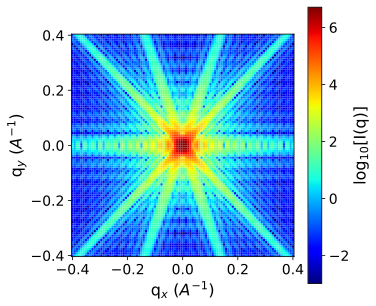

In [23]:
Iq = call_kernel(phi=20, theta=90, radius=200)

fig, ax = plt.subplots()
im = ax.pcolormesh(data2d.qx_data.reshape(2*int(num_q/2), -1), data2d.qy_data.reshape(2*int(num_q/2), -1), np.log10(Iq.reshape(2*int(num_q/2), -1)))
fig.colorbar(im, label='log$_{10}$[I(q)]')

ratio = 1.0
x_min, x_max = (np.min(data2d.qx_data), np.max(data2d.qx_data))
y_min, y_max = (np.min(data2d.qy_data), np.max(data2d.qy_data))
ax.set_aspect(abs((x_max-x_min)/(y_min-y_max))*ratio)

plt.xlabel("q$_x$ ($A^{-1}$)")
plt.ylabel("q$_y$ ($A^{-1}$)")

plt.show()

### truncated octahedron

In [6]:
modelname="truncated_octahedron"

In [7]:
kernel = sasmodels.core.load_model(modelname)
call_kernel = sasmodels.direct_model.DirectModel(data2d, kernel)
kernel.info.parameters.defaults

{'scale': 1,
 'background': 0.001,
 'sld': 126.0,
 'sld_solvent': 9.4,
 'radius_a': 400,
 'b2a_ratio': 1,
 'c2a_ratio': 1,
 'truncation': 0,
 'theta': 0,
 'phi': 0,
 'psi': 0,
 'up_frac_i': 0.0,
 'up_frac_f': 0.0,
 'up_theta': 90.0,
 'up_phi': 0.0,
 'sld_M0': 0.0,
 'sld_mtheta': 0.0,
 'sld_mphi': 0.0,
 'sld_solvent_M0': 0.0,
 'sld_solvent_mtheta': 0.0,
 'sld_solvent_mphi': 0.0}

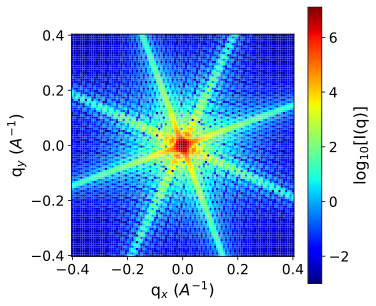

In [8]:
Iq = call_kernel(phi=20, theta=90, radius_a=200)

fig, ax = plt.subplots()
im = ax.pcolormesh(data2d.qx_data.reshape(2*int(num_q/2), -1), data2d.qy_data.reshape(2*int(num_q/2), -1), np.log10(Iq.reshape(2*int(num_q/2), -1)))
fig.colorbar(im, label='log$_{10}$[I(q)]')

ratio = 1.0
x_min, x_max = (np.min(data2d.qx_data), np.max(data2d.qx_data))
y_min, y_max = (np.min(data2d.qy_data), np.max(data2d.qy_data))
ax.set_aspect(abs((x_max-x_min)/(y_min-y_max))*ratio)

plt.xlabel("q$_x$ ($A^{-1}$)")
plt.ylabel("q$_y$ ($A^{-1}$)")

plt.show()

### new prism model including angles

In [9]:
modelname="prism"

In [10]:
kernel = sasmodels.core.load_model(modelname)
call_kernel = sasmodels.direct_model.DirectModel(data2d, kernel)
kernel.info.parameters.defaults

{'scale': 1,
 'background': 0.001,
 'sld': 126.0,
 'sld_solvent': 9.4,
 'n_sides': 5,
 'radius_average': 500,
 'length': 5000,
 'theta': 0,
 'phi': 0,
 'psi': 0}

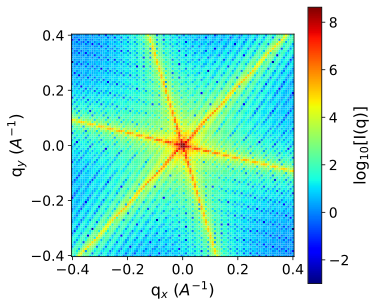

In [15]:
Iq = call_kernel(n_sides=3,phi=13)

fig, ax = plt.subplots()
im = ax.pcolormesh(data2d.qx_data.reshape(2*int(num_q/2), -1), data2d.qy_data.reshape(2*int(num_q/2), -1), np.log10(Iq.reshape(2*int(num_q/2), -1)))
fig.colorbar(im, label='log$_{10}$[I(q)]')

ratio = 1.0
x_min, x_max = (np.min(data2d.qx_data), np.max(data2d.qx_data))
y_min, y_max = (np.min(data2d.qy_data), np.max(data2d.qy_data))
ax.set_aspect(abs((x_max-x_min)/(y_min-y_max))*ratio)

plt.xlabel("q$_x$ ($A^{-1}$)")
plt.ylabel("q$_y$ ($A^{-1}$)")

plt.show()